# Bonus Hands-on: OpenVLA Input → 7-DoF Action

Notebook ini menjalankan **OpenVLA-7B** di Google Colab dan dioptimalkan untuk **T4 GPU**.

Versi ini:

- mount Google Drive,
- mencari folder `Bonus` secara otomatis,
- berpindah ke folder project,
- menyimpan semua hasil ke `Bonus/results/`,
- menggunakan 4-bit quantization agar lebih hemat VRAM,
- menampilkan visualisasi action,
- dan menyimpan hasil inference.


## 1. Gunakan T4 GPU Runtime

Pilih:

```text
Runtime → Change runtime type → T4 GPU
```

Jika sebelumnya terjadi `CUDA out of memory`, lakukan:

```text
Runtime → Restart session
```

sebelum menjalankan notebook dari awal.


## 2. Mount Google Drive dan Tentukan Folder Bonus

Notebook ini **tidak mencari file secara rekursif di seluruh Google Drive**.

Cukup isi `VLA_ROOT_DIR` dengan path folder `Vision-Language-Action Models`. Folder `Bonus` akan diambil langsung dari sana.


In [1]:
# Mount Google Drive.
from google.colab import drive

drive.mount(
    "/content/drive"
)

# Import library untuk path.
import os
import sys
from pathlib import Path

# ============================================================
# UBAH HANYA PATH INI.
# Copy path folder "Vision-Language-Action Models" dari panel
# Files Google Colab, lalu paste di sini.
# ============================================================
VLA_ROOT_DIR = Path(
    "/content/drive/MyDrive/00. Artificial Intelligence (AI)/"
    "Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/"
    "Bagian 4 — Bagaimana Robot Mengambil Keputusan?/"
    "Handson/Vision-Language-Action Models"
)

# Folder Bonus.
PROJECT_DIR = (
    VLA_ROOT_DIR
    / "Bonus"
)

# File utama yang harus tersedia.
required_files = [
    "openvla_inference.py",
    "visualize_action.py",
    "requirements.txt",
]

# Cek root project.
if not VLA_ROOT_DIR.exists():
    raise FileNotFoundError(
        "Vision-Language-Action Models directory not found:\n"
        f"{VLA_ROOT_DIR}\n\n"
        "Copy the folder path from the Colab Files panel "
        "and update VLA_ROOT_DIR."
    )

# Cek folder Bonus.
if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        "Bonus directory not found:\n"
        f"{PROJECT_DIR}"
    )

# Cek file utama.
missing_files = [
    filename
    for filename in required_files
    if not (PROJECT_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following Bonus files are missing:\n"
        + "\n".join(
            f"- {filename}"
            for filename in missing_files
        )
    )

# Pindah ke folder Bonus.
os.chdir(
    PROJECT_DIR
)

# Tambahkan folder Bonus ke Python import path.
project_path = str(
    PROJECT_DIR
)

if project_path not in sys.path:
    sys.path.insert(
        0,
        project_path,
    )

print(
    "Bonus directory:",
    PROJECT_DIR,
)

print(
    "Current working directory:",
    Path.cwd(),
)

print(
    "\nProject setup completed."
)


Mounted at /content/drive
Bonus directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus
Current working directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus

Project setup completed.


## 3. Verifikasi Isi Folder Bonus

Cell berikut hanya memeriksa folder Bonus yang sudah ditentukan. Tidak ada scanning ke Google Drive.


In [2]:
print(
    "Required files:"
)

for filename in [
    "openvla_inference.py",
    "visualize_action.py",
    "requirements.txt",
]:
    print(
        f"- {filename}: OK"
    )

print(
    "\nBonus project setup completed."
)


Required files:
- openvla_inference.py: OK
- visualize_action.py: OK
- requirements.txt: OK

Bonus project setup completed.


## Install Dependencies

Notebook ini **tidak menggunakan `requirements-min.txt` resmi OpenVLA secara langsung** pada Colab modern.

File resmi tersebut masih mem-pin `transformers==4.40.1` dan `tokenizers==0.19.1`. Pada runtime Python Colab yang lebih baru, `tokenizers==0.19.1` dapat tidak memiliki wheel yang cocok dan pip kemudian mencoba melakukan build dari source.

Untuk hands-on ini digunakan stack inference yang lebih kompatibel dengan Colab modern:

```text
transformers 4.49.0
tokenizers 0.21.4
timm 0.9.10
accelerate 0.26.0
bitsandbytes
```

`transformers` sengaja dipertahankan **di bawah 4.50** untuk menghindari perubahan generation cache yang dapat mengganggu OpenVLA lama.


In [3]:
# Cek versi Python yang digunakan Colab.
import sys

print(
    "Python version:",
    sys.version,
)

# Upgrade tooling pip.
!python -m pip install -q --upgrade pip setuptools wheel

# ============================================================
# IMPORTANT
# Jangan install requirements-min.txt OpenVLA secara langsung
# pada Colab modern.
#
# requirements-min.txt resmi masih mem-pin:
#   transformers==4.40.1
#   tokenizers==0.19.1
#
# tokenizers 0.19.1 dapat gagal dibuild pada Python Colab modern.
#
# Untuk inference demo ini kita gunakan stack yang lebih baru,
# tetapi tetap di bawah Transformers 4.50.
# ============================================================

!python -m pip install -q \
  "transformers==4.49.0" \
  "tokenizers==0.21.4" \
  "timm==0.9.10" \
  "accelerate==0.26.0" \
  "bitsandbytes>=0.45.0" \
  "huggingface_hub>=0.25.0" \
  "safetensors>=0.4.0" \
  sentencepiece \
  protobuf \
  pillow \
  numpy \
  matplotlib

print(
    "Dependency installation completed."
)


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 28.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu130 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 whic

In [4]:
# Verifikasi dependency.
import torch
import transformers
import tokenizers
import timm
import accelerate
import bitsandbytes as bnb

print(
    "torch:",
    torch.__version__,
)

print(
    "transformers:",
    transformers.__version__,
)

print(
    "tokenizers:",
    tokenizers.__version__,
)

print(
    "timm:",
    timm.__version__,
)

print(
    "accelerate:",
    accelerate.__version__,
)

print(
    "bitsandbytes:",
    bnb.__version__,
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )
else:
    raise RuntimeError(
        "GPU is not enabled. Select a T4 GPU runtime."
    )


torch: 2.11.0+cu130
transformers: 4.49.0
tokenizers: 0.21.4
timm: 0.9.10
accelerate: 0.26.0
bitsandbytes: 0.50.2
GPU: Tesla T4


## 5. Import Library dan Bersihkan Memory


In [5]:
# Mengurangi risiko fragmentasi CUDA memory.
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# Import library.
import gc
import json
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files
from transformers import (
    AutoModelForVision2Seq,
    AutoProcessor,
    BitsAndBytesConfig,
)

# Folder hasil di Google Drive.
RESULTS_DIR = (
    PROJECT_DIR
    / "results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Bersihkan memory.
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

    print(
        "Allocated before loading:",
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB",
    )
else:
    raise RuntimeError(
        "Please enable a GPU runtime."
    )

print(
    "Results directory:",
    RESULTS_DIR,
)


GPU: Tesla T4
Allocated before loading: 0.00 GB
Results directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus/results


## 6. Upload RGB Image


Saving red.jpg to red (1).jpg


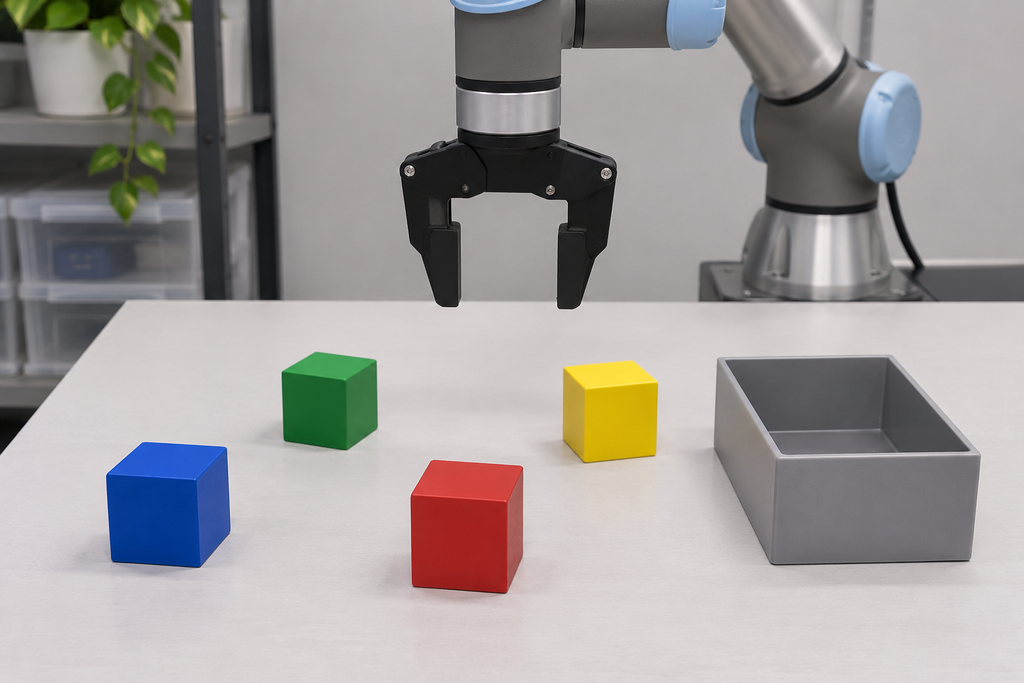

Image loaded from: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus/red (1).jpg
Image size: (1024, 683)


In [6]:
uploaded = files.upload()

image_name = list(
    uploaded.keys()
)[0]

image_path = (
    Path.cwd()
    / image_name
)

if not image_path.exists():
    raise FileNotFoundError(
        f"Uploaded image was not found: {image_path}"
    )

# Buka image.
image = Image.open(
    image_path
).convert(
    "RGB"
)

# Resize agar inference lebih ringan.
image.thumbnail(
    (1024, 1024),
    Image.Resampling.LANCZOS,
)

display(
    image
)

print(
    "Image loaded from:",
    image_path,
)

print(
    "Image size:",
    image.size,
)


## 7. Language Instruction


In [7]:
instruction = (
    "pick up the red object"
)

print(
    "Instruction:",
    instruction,
)


Instruction: pick up the red object


## 8. Load OpenVLA-7B dalam 8-bit

OpenVLA dimuat dalam **8-bit** agar lebih ringan untuk Google Colab T4.

Model menggunakan FP16 untuk input visual dan compute path yang tidak terkuantisasi.


In [8]:
MODEL_ID = "openvla/openvla-7b"

# Konfigurasi 8-bit.
quantization_config = BitsAndBytesConfig(
    load_in_8bit=True,
)

# Load processor.
processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
)

# Load OpenVLA dalam 8-bit.
vla = AutoModelForVision2Seq.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True,
    trust_remote_code=True,
    device_map="auto",
)

vla.eval()

print("OpenVLA loaded in 8-bit.")

print(
    "GPU memory allocated:",
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB",
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


processor_config.json:   0%|          | 0.00/130 [00:00<?, ?B/s]

processing_prismatic.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/openvla/openvla-7b:
- processing_prismatic.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


preprocessor_config.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00003.safetensors:   0%|          | 0.00/6.97G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/1.16G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

OpenVLA loaded in 8-bit.
GPU memory allocated: 7.40 GB


In [9]:
# ============================================================
# Perbaikan dtype lm_head untuk Google Colab T4.
#
# Pada beberapa kombinasi OpenVLA + Transformers + bitsandbytes,
# lm_head dapat tetap menggunakan BF16 walaupun model dimuat
# dengan torch_dtype=float16.
#
# Hal ini dapat menghasilkan error:
#   expected mat1 and mat2 to have the same dtype
#   float != BFloat16
#
# Untuk T4, kita buat salinan lm_head dalam FP16 secara eksplisit.
# ============================================================

# Hapus hook lama jika cell ini dijalankan ulang.
if "lm_head_hook" in globals():
    try:
        lm_head_hook.remove()
    except Exception:
        pass

old_lm_head = (
    vla.language_model.lm_head
)

print(
    "Original lm_head dtype:",
    old_lm_head.weight.dtype,
)

print(
    "Original lm_head device:",
    old_lm_head.weight.device,
)

# T4 menggunakan CUDA FP16.
HEAD_DEVICE = torch.device(
    "cuda:0"
)

# Buat lm_head baru dalam FP16.
fp16_lm_head = torch.nn.Linear(
    old_lm_head.in_features,
    old_lm_head.out_features,
    bias=old_lm_head.bias is not None,
    device=HEAD_DEVICE,
    dtype=torch.float16,
)

# Salin weight dan bias lama ke FP16.
with torch.no_grad():
    fp16_lm_head.weight.copy_(
        old_lm_head.weight.detach().to(
            device=HEAD_DEVICE,
            dtype=torch.float16,
        )
    )

    if old_lm_head.bias is not None:
        fp16_lm_head.bias.copy_(
            old_lm_head.bias.detach().to(
                device=HEAD_DEVICE,
                dtype=torch.float16,
            )
        )

# Ganti lm_head lama.
vla.language_model.lm_head = (
    fp16_lm_head
)

# Pastikan hidden state yang masuk ke lm_head
# selalu mengikuti dtype dan device weight lm_head.
def cast_lm_head_input(
    module,
    args,
):
    hidden_states = args[0]

    hidden_states = hidden_states.to(
        device=module.weight.device,
        dtype=module.weight.dtype,
    )

    return (
        hidden_states,
        *args[1:],
    )

lm_head_hook = (
    vla.language_model.lm_head
    .register_forward_pre_hook(
        cast_lm_head_input
    )
)

print(
    "Patched lm_head dtype:",
    vla.language_model.lm_head.weight.dtype,
)

print(
    "Patched lm_head device:",
    vla.language_model.lm_head.weight.device,
)

assert (
    vla.language_model.lm_head.weight.dtype
    == torch.float16
)

assert (
    vla.language_model.lm_head.weight.device.type
    == "cuda"
)

print(
    "T4 lm_head patch completed."
)


Original lm_head dtype: torch.bfloat16
Original lm_head device: cuda:0
Patched lm_head dtype: torch.float16
Patched lm_head device: cuda:0
T4 lm_head patch completed.


## 9. Format Multimodal Input


In [10]:
# Membuat prompt OpenVLA.
prompt = (
    "In: What action should the robot take to "
    f"{instruction.lower()}?\nOut:"
)

# Untuk T4 + OpenVLA 8-bit gunakan float16.
device = torch.device("cuda:0")

# Process image dan text.
inputs = processor(
    prompt,
    image,
    return_tensors="pt",
)

# Pindahkan seluruh BatchFeature ke GPU.
# Floating-point tensor seperti pixel_values otomatis menjadi float16.
inputs = inputs.to(
    device=device,
    dtype=torch.float16,
)

print("Input prepared.")

# Verifikasi sebelum inference.
for key, value in inputs.items():
    if torch.is_tensor(value):
        print(
            f"{key:20s}",
            "| dtype:",
            value.dtype,
            "| device:",
            value.device,
            "| shape:",
            tuple(value.shape),
        )


Input prepared.
input_ids            | dtype: torch.int64 | device: cuda:0 | shape: (1, 19)
attention_mask       | dtype: torch.int64 | device: cuda:0 | shape: (1, 19)
pixel_values         | dtype: torch.float16 | device: cuda:0 | shape: (1, 6, 224, 224)


### FP16 consistency check

Sebelum inference, notebook memastikan `pixel_values` dan `lm_head` menggunakan FP16 pada GPU. Ini mencegah mismatch `float32`, `float16`, dan `bfloat16` pada T4.


## 10. Predict 7-DoF Action


In [11]:
# Pastikan dtype penting sebelum inference.
print(
    "pixel_values dtype:",
    inputs["pixel_values"].dtype,
)

print(
    "lm_head dtype:",
    vla.language_model.lm_head.weight.dtype,
)

print(
    "lm_head device:",
    vla.language_model.lm_head.weight.device,
)

# Jalankan inference.
with torch.inference_mode():
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
    ):
        action = vla.predict_action(
            **inputs,
            unnorm_key="bridge_orig",
            do_sample=False,
        )

# Konversi hasil ke NumPy.
action = np.asarray(
    action,
    dtype=np.float32,
)

print(
    "Action shape:",
    action.shape,
)

print(
    "Raw action:",
    action,
)


pixel_values dtype: torch.float16
lm_head dtype: torch.float16
lm_head device: cuda:0


Action shape: (7,)
Raw action: [-7.1426886e-03  1.1231231e-02  1.8581470e-05  3.0540903e-03
 -1.2168298e-02  1.6051270e-02  9.9607843e-01]


## 11. Membaca Action

Urutan action:

```text
[Δx, Δy, Δz, Δroll, Δpitch, Δyaw, gripper]
```


In [12]:
labels = [
    "Δx",
    "Δy",
    "Δz",
    "Δroll",
    "Δpitch",
    "Δyaw",
    "gripper",
]

for label, value in zip(
    labels,
    action,
):
    print(
        f"{label:8s}: "
        f"{value: .6f}"
    )


Δx      : -0.007143
Δy      :  0.011231
Δz      :  0.000019
Δroll   :  0.003054
Δpitch  : -0.012168
Δyaw    :  0.016051
gripper :  0.996078


## 12. Visualisasi 7-DoF Action


Action bar chart saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus/results/action_bar_chart.png


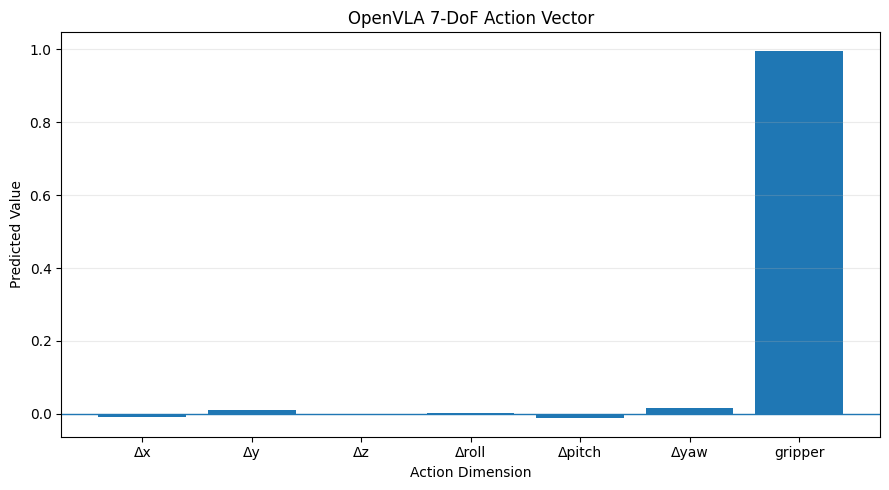

In [13]:
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    labels,
    action,
)

plt.axhline(
    0.0,
    linewidth=1,
)

plt.xlabel(
    "Action Dimension"
)

plt.ylabel(
    "Predicted Value"
)

plt.title(
    "OpenVLA 7-DoF Action Vector"
)

plt.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

action_chart_path = (
    RESULTS_DIR
    / "action_bar_chart.png"
)

plt.savefig(
    action_chart_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    "Action bar chart saved to:",
    action_chart_path,
)

plt.show()
plt.close()


## 13. Visualisasi Translasi End-Effector


Translation vector saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus/results/translation_vector.png


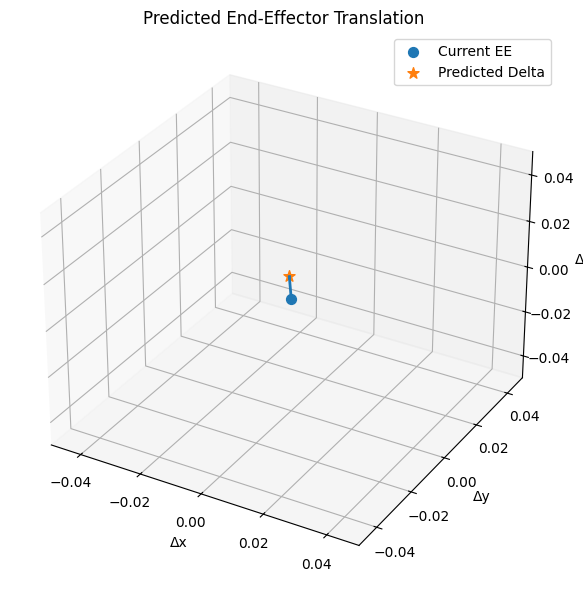

In [14]:
dx, dy, dz = action[:3]

magnitude = max(
    float(
        np.linalg.norm(
            action[:3]
        )
    ),
    1e-6,
)

limit = max(
    0.05,
    magnitude * 1.35,
)

fig = plt.figure(
    figsize=(6, 6)
)

ax = fig.add_subplot(
    111,
    projection="3d",
)

ax.quiver(
    0,
    0,
    0,
    dx,
    dy,
    dz,
    arrow_length_ratio=0.12,
    linewidth=2,
)

ax.scatter(
    [0],
    [0],
    [0],
    s=50,
    label="Current EE",
)

ax.scatter(
    [dx],
    [dy],
    [dz],
    s=70,
    marker="*",
    label="Predicted Delta",
)

ax.set_xlim(
    -limit,
    limit,
)

ax.set_ylim(
    -limit,
    limit,
)

ax.set_zlim(
    -limit,
    limit,
)

ax.set_xlabel("Δx")
ax.set_ylabel("Δy")
ax.set_zlabel("Δz")

ax.set_title(
    "Predicted End-Effector Translation"
)

ax.legend()

plt.tight_layout()

translation_path = (
    RESULTS_DIR
    / "translation_vector.png"
)

plt.savefig(
    translation_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    "Translation vector saved to:",
    translation_path,
)

plt.show()
plt.close()


## 14. Save Raw Action


In [15]:
npy_path = (
    RESULTS_DIR
    / "openvla_action.npy"
)

json_path = (
    RESULTS_DIR
    / "openvla_action.json"
)

summary_path = (
    RESULTS_DIR
    / "action_summary.txt"
)

np.save(
    npy_path,
    action,
)

record = {
    "instruction": instruction,
    "unnorm_key": "bridge_orig",
    "action_labels": labels,
    "action": [
        float(x)
        for x in action
    ],
}

json_path.write_text(
    json.dumps(
        record,
        indent=2,
    ),
    encoding="utf-8",
)

summary_lines = [
    "OpenVLA 7-DoF Action Summary",
    "",
]

for label, value in zip(
    labels,
    action,
):
    summary_lines.append(
        f"{label:8s}: {value: .6f}"
    )

summary_path.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)

print(
    "NumPy action saved to:",
    npy_path,
)

print(
    "JSON action saved to:",
    json_path,
)

print(
    "Action summary saved to:",
    summary_path,
)

print(
    "Results directory:",
    RESULTS_DIR,
)


NumPy action saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus/results/openvla_action.npy
JSON action saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus/results/openvla_action.json
Action summary saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Models/Bonus/results/action_summary.txt
Results directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Vision-Language-Action Mo